In [4]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os

from diffusion_mlp_cnn.models.utils import Data
from diffusion_mlp_cnn.models.MLP import MLPDiffusionRegressor

In [5]:
plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

# Load data

### Training and single-step validation data

In [6]:
initializations = ["gaussian", "uniform", "cosine"]
training_data = Data(
    initializations,
    path="training_data",
    model_type="MLP"
)
print(f"Input training data shape (N_samples, Nx): "
      f"{training_data.X_numpy.shape}")
print(f"Output training data shape (N_samples, Nx): "
      f"{training_data.Y_numpy.shape}")
print(f"Training data dtype (input, output): "
      f"({training_data.X.dtype}, {training_data.Y.dtype})")

Input training data shape (N_samples, Nx): (1980, 201)
Output training data shape (N_samples, Nx): (1980, 201)
Training data dtype (input, output): (torch.float32, torch.float32)


In [7]:
validation_data = Data(
    initializations,
    path="validation_data",
    model_type="MLP"
)
print(f"Input single step validation data shape (N_samples, Nx): "
      f"{validation_data.X_numpy.shape}")
print(f"Output single step validation data shape (N_samples, Nx): "
      f"{validation_data.Y_numpy.shape}")
print(f"single step validation data dtype (input, output): "
      f"({validation_data.X.dtype}, {validation_data.Y.dtype})")

Input single step validation data shape (N_samples, Nx): (360, 201)
Output single step validation data shape (N_samples, Nx): (360, 201)
single step validation data dtype (input, output): (torch.float32, torch.float32)


### Full time series data

Initializations: Gaussian, uniform block and cosine

# Training performance

In [8]:
os.makedirs("figures", exist_ok=True)

In [9]:
epochs = {}
training_MSE_loss = {}
training_L2_error = {}
validation_L2_error = {}
for activation in ["relu", "tanh"]:
    perf_data = np.loadtxt(
        "mlp_" + activation + "_training_perf.txt",
        dtype=np.float32
    )
    epochs.update({activation: perf_data[:, 0]})
    training_MSE_loss.update({activation: perf_data[:, 1]})
    training_L2_error.update({activation: perf_data[:, 2]})
    validation_L2_error.update({activation: perf_data[:, 3]})

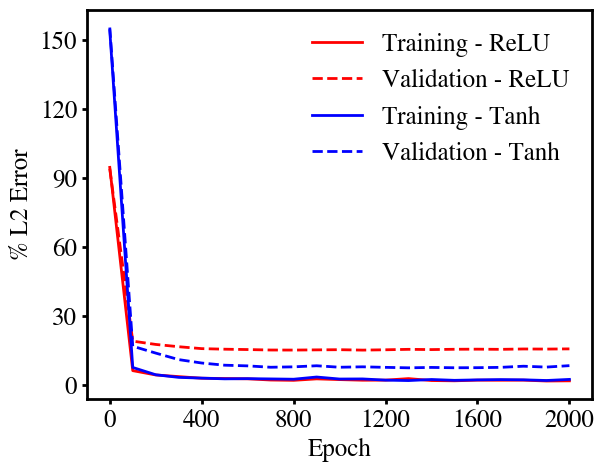

In [10]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs["relu"], training_L2_error["relu"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training - ReLU")
ax.plot(epochs["relu"], validation_L2_error["relu"] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Validation - ReLU")
ax.plot(epochs["tanh"], training_L2_error["tanh"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Training - Tanh")
ax.plot(epochs["tanh"], validation_L2_error["tanh"] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation - Tanh")
ax.set_xlabel(r"Epoch", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_mlp.pdf")
plt.show()

In [11]:
print(f"Minimum single-step validation error")
print(f"ReLU: {np.min(validation_L2_error["relu"]) * 100:.2f} %")
print(f"Tanh: {np.min(validation_L2_error["tanh"]) * 100:.2f} %")

Minimum single-step validation error
ReLU: 15.03 %
Tanh: 7.31 %


# Load trained MLP

Saved when the single-step validation error was minimum \
Activations: ReLU, Tanh \
width: 128

In [12]:
width = 128
mlp_models = {}
for activation in ["relu", "tanh"]:
    model = MLPDiffusionRegressor(
        training_data.Nx,
        width,
        activation=activation
    )
    model.load_state_dict(
        torch.load("mlp_" + activation + ".pt",
                   map_location="cpu", weights_only=True)
    )
    mlp_models.update({activation: model})

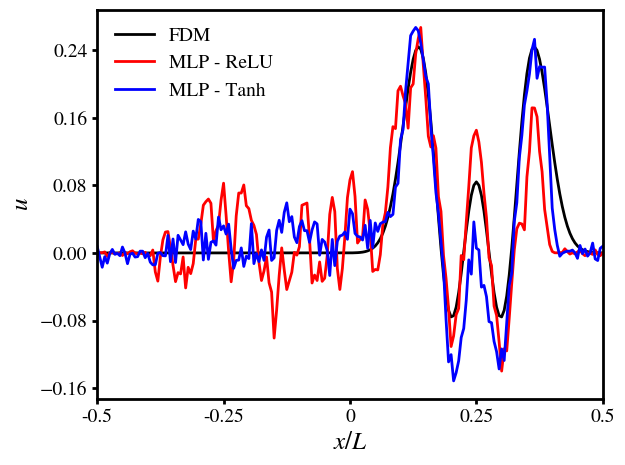

In [13]:
L = 200
n_sample = 359
data = validation_data
Y_check_relu = mlp_models["relu"].forward(
    data.X[n_sample]
).detach().numpy()
Y_check_tanh = mlp_models["tanh"].forward(
    data.X[n_sample]
).detach().numpy()
x = np.linspace(-L/2, L/2, 201)
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(x / L, data.Y[n_sample], linewidth=2, color="black",
        linestyle="solid", label=r"FDM", zorder=1)
ax.plot(x / L, Y_check_relu, linewidth=2, color="red",
        linestyle="solid", label=r"MLP - ReLU", zorder=1)
ax.plot(x / L, Y_check_tanh, linewidth=2, color="blue",
        linestyle="solid", label=r"MLP - Tanh", zorder=1)
ax.set_xlabel(r"$x / L$", fontsize=18)
ax.set_ylabel(r"$u$", fontsize=18)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

# Auto-regressive testing

In [14]:
l2_error_time = {}
mass_err_mlp = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
for activation  in ["relu", "tanh"]:
    l2_error_time.update({activation: {}})
    mass_err_mlp.update({activation: {}})
    u_pred.update({activation: {}})
    model = mlp_models[activation]
    model.eval()
    with torch.inference_mode():
        for init_type in initializations:
            data = np.load("testing_data/" + init_type + ".npz")
            u = data["u"]
            Nx = data["Nx"]
            snaps = data["snaps"]
            u_tensor = torch.from_numpy(u)
            u_pred_tensor = u_tensor.clone().detach()
            for snap in range(1, u_tensor.shape[0]):
                u_pred_tensor[snap] = model(
                    u_pred_tensor[snap - 1]
                )
            diff = u_pred_tensor.detach().numpy() - u
            l2_error = np.linalg.norm(diff, axis=1) /\
                (np.linalg.norm(u, axis=1) + 1e-10)
            l2_error_time[activation].update({init_type: l2_error})
            u_pred[activation].update(
                {init_type: u_pred_tensor.detach().numpy()}
            )
            u_fdm.update({init_type: u})
            mass_fdm = np.sum(u, axis=1)
            mass_err_fdm.update(
                {init_type: (mass_fdm - mass_fdm[0]) / mass_fdm[0]}
            )
            mass_mlp = np.sum(u_pred[activation][init_type], axis=1)
            mass_err_mlp[activation].update(
                {init_type: (mass_mlp - mass_mlp[0]) / mass_mlp[0]}
            )
times = np.arange(0, snaps, 1)  # All must have same time dimension

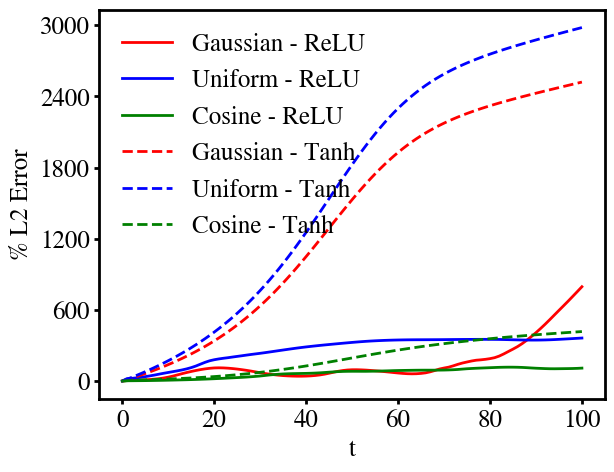

In [15]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, l2_error_time["relu"]["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian - ReLU")
ax.plot(times, l2_error_time["relu"]["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform - ReLU")
ax.plot(times, l2_error_time["relu"]["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine - ReLU")
ax.plot(times, l2_error_time["tanh"]["gaussian"] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Gaussian - Tanh")
ax.plot(times, l2_error_time["tanh"]["uniform"] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Uniform - Tanh")
ax.plot(times, l2_error_time["tanh"]["cosine"] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Cosine - Tanh")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/autoregressive_mlp.pdf")
plt.show()

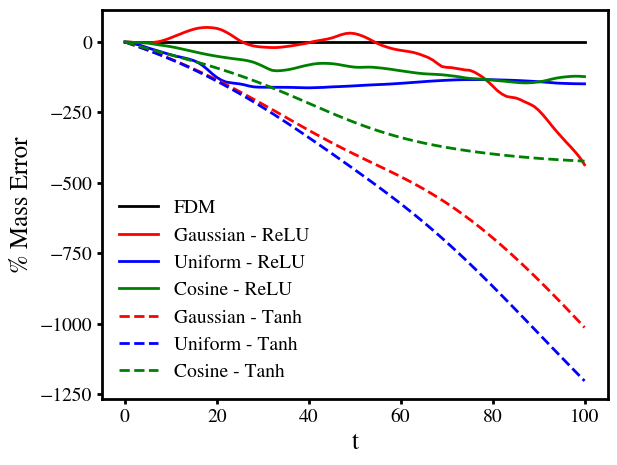

In [16]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, mass_err_fdm["gaussian"] * 100, linewidth=2,
        color="black", linestyle="solid", label=r"FDM")
ax.plot(times, mass_err_mlp["relu"]["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian - ReLU")
ax.plot(times, mass_err_mlp["relu"]["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform - ReLU")
ax.plot(times, mass_err_mlp["relu"]["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine - ReLU")
ax.plot(times, mass_err_mlp["tanh"]["gaussian"] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Gaussian - Tanh")
ax.plot(times, mass_err_mlp["tanh"]["uniform"] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Uniform - Tanh")
ax.plot(times, mass_err_mlp["tanh"]["cosine"] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Cosine - Tanh")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% Mass Error", fontsize=18)
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

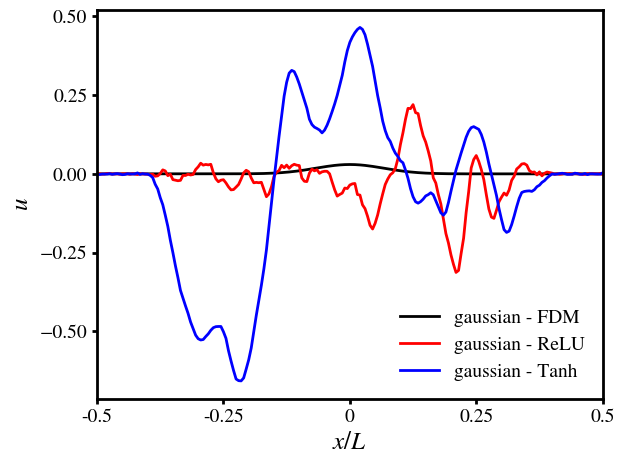

In [17]:
t = 100
init_type = "gaussian"
x = np.linspace(-L/2, L/2, 201)
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(x / L, u_fdm[init_type][t], linewidth=2, color="black",
        linestyle="solid", label=init_type + r" - FDM", zorder=1)
ax.plot(x / L, u_pred["relu"][init_type][t], linewidth=2, color="red",
        linestyle="solid", label=init_type + r" - ReLU", zorder=1)
ax.plot(x / L, u_pred["tanh"][init_type][t], linewidth=2, color="blue",
        linestyle="solid", label=init_type + r" - Tanh", zorder=1)
ax.set_xlabel(r"$x / L$", fontsize=18)
ax.set_ylabel(r"$u$", fontsize=18)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

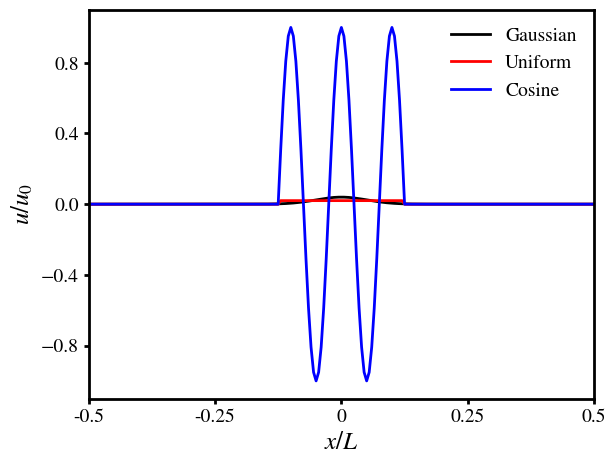

In [18]:
t = 0
x = np.linspace(-L/2, L/2, 201)
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(x / L, u_fdm["gaussian"][t], linewidth=2, color="black",
        linestyle="solid", label="Gaussian", zorder=1)
ax.plot(x / L, u_pred["relu"]["uniform"][t], linewidth=2, color="red",
        linestyle="solid", label="Uniform", zorder=1)
ax.plot(x / L, u_pred["tanh"]["cosine"][t], linewidth=2, color="blue",
        linestyle="solid", label="Cosine", zorder=1)
ax.set_xlabel(r"$x / L$", fontsize=18)
ax.set_ylabel(r"$u / u_0$", fontsize=18)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()